# Detecting Persistent Product Substitution and Potential Cannibalization: A project plan using change-point analysis of household grocery purchases
#### By Mattheus Marcus Contreras and Nikkei Jane Espina


### Executive Summary

Retailers can observe that sales changed, but not immediately whether the change reflects genuine category growth, temporary promotion response, or households switching between competing brands. This project develops an interpretable framework that first detects structural changes in household purchase behavior, then identifies substitution patterns, and finally measures whether the new behavior persists.

### Research Questions

1. At what points do households exhibit statistically meaningful changes in purchasing patterns within selected product categories?
2. After a detected change point, do households shift purchases from one competing product or brand to another?
3. Are gains in one product accompanied by losses in a competing product without substantial category growth?
4. Are detected shifts temporary, or do households maintain the new purchasing pattern?
5. Are temporary and persistent shifts associated with differences in price or promotional exposure?


### Conceptual Framework

##### Stage 1: Detect
Identify when a household’s brand or product allocation changes significantly.
##### Stage 2: Classify
Determine whether the event reflects substitution, category expansion or contraction, cessation, or temporary switching.
##### Stage 3: Evaluate potential cannibalization
Test whether the gaining product’s increase corresponds with a competing product’s decline while category demand remains approximately stable.
##### Stage 4: Measure persistence
Determine whether the household maintains the post-change state or reverts to its previous behavior.
Interpretation rule  Use “consistent with potential cannibalization,” not “Product B caused Product A’s decline,” unless a causal design is added.


### Operational Definitions

#### Change point
A week or purchase occasion at which a household’s purchasing pattern moves from one relatively stable state to another. Example: Brand A receives 80% of category purchases before Week 13 and 25% afterward, while Brand B becomes dominant.

#### Substitution
- Product or Brand A share/quantity declines.
- Product or Brand B share/quantity increases.
- A and B compete within the same category.
- Total category purchasing does not increase proportionately.
Initial rule for testing: A decreases by at least 20 percentage points, B increases by at least 20 percentage points, and total category volume remains within ±20%. These thresholds must be tested through sensitivity analysis.

#### Potential cannibalization
A stronger business interpretation of substitution, used when gains and losses occur among direct competitors, category demand remains stable, the pattern repeats across households, and it is not merely a short promotional spike.

#### Persistence and reversion
Primary persistence rule: the new dominant brand is maintained for at least eight weeks and at least 60% of post-change category purchases follow the new pattern. A purchase-occasion version should require the next three to five category purchases to support the new state. Reversion occurs when allocation returns to within 10 percentage points of the pre-change state.


In [ ]:
### Setup and Loading Data

import numpy as np
import pandas as pd
import sqlite3

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

pd.set_option("display.max_columns", None)

transactions = pd.read_csv("C:/Users/ASUS VivoBook/OneDrive/Desktop/pmdsc/DS_207_MiniProject/data/transaction_data.csv")
products = pd.read_csv("C:/Users/ASUS VivoBook/OneDrive/Desktop/pmdsc/DS_207_MiniProject/data/product.csv")
households = pd.read_csv("C:/Users/ASUS VivoBook/OneDrive/Desktop/pmdsc/DS_207_MiniProject/data/hh_demographic.csv")
coupon = pd.read_csv("C:/Users/ASUS VivoBook/OneDrive/Desktop/pmdsc/DS_207_MiniProject/data/coupon.csv")
coupon_redempt = pd.read_csv("C:/Users/ASUS VivoBook/OneDrive/Desktop/pmdsc/DS_207_MiniProject/data/coupon_redempt.csv")
campaign_table = pd.read_csv("C:/Users/ASUS VivoBook/OneDrive/Desktop/pmdsc/DS_207_MiniProject/data/campaign_table.csv")
campaign_desc = pd.read_csv("C:/Users/ASUS VivoBook/OneDrive/Desktop/pmdsc/DS_207_MiniProject/data/campaign_desc.csv")

conn = sqlite3.connect(":memory:")

transactions.to_sql("transactions", conn, index=False, if_exists="replace")
products.to_sql("products", conn, index=False, if_exists="replace")
households.to_sql("household", conn, index=False, if_exists="replace")
coupon.to_sql("coupon", conn, index=False, if_exists="replace")
coupon_redempt.to_sql("coupon_redempt", conn, index=False, if_exists="replace")
campaign_table.to_sql("campaign_table", conn, index=False, if_exists="replace")
campaign_desc.to_sql("campaign_desc", conn, index=False, if_exists="replace")

print(transactions.shape)
print(products.shape)
print(households.shape)

### Transaction Table
print(transactions.info())
print(transactions.isnull().sum())
print(transactions.duplicated().sum())
print(transactions.describe())

### Product table
print(products.info())
print(products.isnull().sum())
print(products.duplicated().sum())

##Household table
print(households.info())
print(households.isnull().sum())
print(households.duplicated().sum())


(2595732, 12)
(92353, 7)
(801, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB
None
household_key        0
BASKET_ID            0
DAY                  0
PRODUCT_ID           0
QUANTITY             0
SALES_VALUE          0
STORE_ID             0
RETAIL_DISC          0
TRANS_TIME           0
WEEK_NO              0
COUPON_DISC          0
COUPON_MATCH_DISC    0
dtype: int64
0
       household_key     BASKET_ID           DAY    PRODU

# Building Master Data

In [5]:
query = ''' 
SELECT t.*, p.manufacturer, p.department, p.brand, p.commodity_desc, p.sub_commodity_desc, p.curr_size_of_product,
h.classification_1, h.classification_2, h.classification_3, h.homeowner_desc, h.classification_5, h.classification_4,
h.kid_category_desc,
c.coupon_upc, c.campaign,
cr.day AS redemption_day,
cd.start_day, cd.end_day,
CASE
  WHEN cr.household_key IS NOT NULL THEN 1
  ELSE 0
END AS coupon_redeemed
FROM transactions t
LEFT JOIN products p
ON t.product_id = p.product_id
LEFT JOIN household h
ON t.household_key = h.household_key
LEFT JOIN coupon c
    ON t.product_id = c.product_id
LEFT JOIN coupon_redempt cr
    ON c.coupon_upc = cr.coupon_upc
    AND t.household_key = cr.household_key
LEFT JOIN campaign_table ct
    ON t.household_key = ct.household_key
LEFT JOIN campaign_desc cd
    ON ct.campaign= cd.campaign;
'''
df = pd.read_sql_query(query, conn)

df.shape

df.head()



,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT,classification_1,classification_2,classification_3,HOMEOWNER_DESC,classification_5,classification_4,KID_CATEGORY_DESC,COUPON_UPC,CAMPAIGN
0,2375,26984851472,1,1004906,1,1.39,364,-0.6,1631,1,0.0,0.0,69,PRODUCE,Private,POTATOES,POTATOES RUSSET (BULK&BAG),5 LB,None,None,None,None,None,None,None,1.000009e+10,8.0
1,2375,26984851472,1,1004906,1,1.39,364,-0.6,1631,1,0.0,0.0,69,PRODUCE,Private,POTATOES,POTATOES RUSSET (BULK&BAG),5 LB,None,None,None,None,None,None,None,1.000009e+10,13.0
2,2375,26984851472,1,1004906,1,1.39,364,-0.6,1631,1,0.0,0.0,69,PRODUCE,Private,POTATOES,POTATOES RUSSET (BULK&BAG),5 LB,None,None,None,None,None,None,None,1.000009e+10,18.0
3,2375,26984851472,1,1033142,1,0.82,364,0.0,1631,1,0.0,0.0,2,PRODUCE,National,ONIONS,ONIONS SWEET (BULK&BAG),40 LB,None,None,None,None,None,None,None,1.000009e+10,13.0
4,2375,26984851472,1,1033142,1,0.82,364,0.0,1631,1,0.0,0.0,2,PRODUCE,National,ONIONS,ONIONS SWEET (BULK&BAG),40 LB,None,None,None,None,None,None,None,1.000009e+10,18.0


### Post-Join Profiling

In [ ]:
## Missing Values After Merge
missing = (df.isnull().sum().sort_values(ascending=False))

print(missing[missing > 0])

print(df.duplicated().sum())
print(df.dtypes)
print(df.describe())

Series([], dtype: int64)
0
household_key             int64
BASKET_ID                 int64
DAY                       int64
PRODUCT_ID                int64
QUANTITY                  int64
SALES_VALUE             float64
STORE_ID                  int64
RETAIL_DISC             float64
TRANS_TIME                int64
WEEK_NO                   int64
COUPON_DISC             float64
COUPON_MATCH_DISC       float64
MANUFACTURER              int64
DEPARTMENT               object
BRAND                    object
COMMODITY_DESC           object
SUB_COMMODITY_DESC       object
CURR_SIZE_OF_PRODUCT     object
classification_1         object
classification_2         object
classification_3         object
HOMEOWNER_DESC           object
classification_5         object
classification_4         object
KID_CATEGORY_DESC        object
dtype: object
       household_key     BASKET_ID           DAY    PRODUCT_ID      QUANTITY  \
count   1.427303e+06  1.427303e+06  1.427303e+06  1.427303e+06  1.427303e+06   

### Outlier Analysis


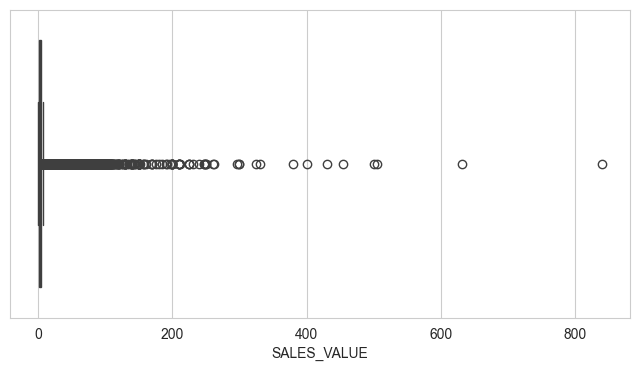

In [ ]:
##Sales Value 
q1 = df["SALES_VALUE"].quantile(.25)

q3 = df["SALES_VALUE"].quantile(.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr

upper = q3 + 1.5 * iqr

sales_outliers = df[
    (df["SALES_VALUE"] < lower)
    |
    (df["SALES_VALUE"] > upper)
]

len(sales_outliers)

##Boxplot

plt.figure(figsize=(8,4))

sns.boxplot(
    x=df["SALES_VALUE"]
)

plt.show()